# 02 · Preprocesamiento — comparación objetiva de variantes

**Objetivo:** decidir qué pasos de preprocesamiento usar, midiendo su efecto sobre el F1 con un **modelo simple y fijo**. No buscamos el mejor modelo, sino **aislar el efecto del preprocesamiento**: lo único que cambia entre experimentos es el texto de entrada.

Parte de las decisiones del `01_EDA` (ver `PROGRESO.md`): D2 (artefactos del CSV), D4 (restauración de palabras dañadas), D5 (normalización), D8 (validación), D9 (lematización como vista extra) y D10.

**Reglas que respeta este notebook:**
- **Sin vectores preentrenados.** spaCy `es_core_news_sm` se usa solo para `lemma_`, `pos_` y `morph`, cargado sin `ner`, `parser` ni `senter`.
- **Todo vectorizador se ajusta dentro de cada fold** (va dentro de un `Pipeline`). Nunca se ajusta con todo el train antes de validar.
- **Los diccionarios se construyen sin etiquetas.** La restauración de palabras usa solo los textos del train.
- Todo recurso queda citado en la celda *Recursos externos*.

**Conceptos que aparecen:**
- **Validación cruzada (k-fold):** se parte el train en *k* = 5 trozos (*folds*). Se entrena con 4 y se evalúa con el que queda, rotando 5 veces.
- **OOF (*out-of-fold*):** la predicción de cada tuit hecha por el modelo que **no** lo vio al entrenar. Juntando las 5 rondas, cada tuit del train tiene exactamente una predicción OOF, y con ellas se calcula un F1 "honesto" sobre todo el train.
- **Estratificación por combinación:** al repartir los folds se mantiene en cada uno la misma proporción de cada combinación de etiquetas (000, 111, 101...). Así ningún fold se queda sin ejemplos de las combinaciones raras (110, 001).
- **Ablación:** partir de la mejor variante y **quitar un paso cada vez** para medir cuánto aporta ese paso por sí solo.

El código reutilizable está en `notebooks/preprocessing.py` (los pasos) y `notebooks/common.py` (folds y métricas).

## 1. Carga, folds y recursos externos

In [1]:
import difflib
import json
import platform
import re
import time
from collections import Counter
from dataclasses import replace

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import spacy
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

import preprocessing as pp
from common import (FIGURES_DIR, LABELS, PROCESSED_DIR, SEED, evaluate_oof, load_test, load_train, make_folds)

np.random.seed(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
LABEL_COLORS = {"HS": "#2a78d6", "TR": "#eb6834", "AG": "#1baf7a"}
ACCENT, MUTED = "#2a78d6", "#a3a29c"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"02_{name}.png", dpi=120, bbox_inches="tight")


print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | spaCy {spacy.__version__} | SEED = {SEED}")

train = load_train()
test = load_test()
HAS_TEST = test is not None
Y = train[LABELS].to_numpy()
print(f"Train: {len(train)} filas | Test: {len(test) if HAS_TEST else 'no disponible'}")

Python 3.14.6 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | spaCy 3.8.16 | SEED = 42
Train: 1731 filas | Test: 1154


### Folds compartidos

`make_folds()` (en `common.py`) reparte el train en 5 folds **estratificados por la combinación de etiquetas** y mantiene en el mismo fold los **casi-duplicados** (tuits iguales tras quitar menciones, URLs y signos). Así un tuit repetido no queda a la vez en entrenamiento y validación, lo que inflaría el F1. La asignación se guarda en `data/processed/folds.csv` y todos los notebooks siguientes la reutilizan.

In [2]:
folds = make_folds(train)
combo = train[LABELS].astype(str).agg("".join, axis=1)
fold_table = pd.crosstab(combo, folds, margins=True, margins_name="total")
fold_table.index.name, fold_table.columns.name = "HS TR AG", "fold"
display(fold_table)

fold,0,1,2,3,4,total
HS TR AG,,,,,,
000,190,190,190,190,189,949
001,5,5,5,6,5,26
100,19,19,18,18,18,92
101,29,29,29,29,29,145
110,6,5,6,5,6,28
111,98,98,98,98,99,491
total,347,346,346,346,346,1731


**Interpretación:** los 5 folds tienen 346–347 tuits y la misma proporción de cada combinación. Incluso las raras quedan repartidas: 001 tiene 5–6 tuits por fold y 110 tiene 5–6. El archivo `data/processed/folds.csv` fija esta asignación para todos los notebooks siguientes.

### Recursos externos

En este notebook **no se usa ningún léxico ni corpus de terceros**. Todos los diccionarios son de elaboración propia y no usan etiquetas. El único recurso externo es el modelo de spaCy.

| Recurso | Tipo | Fuente | Licencia | Uso |
|---|---|---|---|---|
| `MANUAL_RESTORE` (`preprocessing.py`) | Diccionario propio: forma dañada → forma ASCII | Palabras dañadas detectadas en `01_EDA` §4 y §5b | Propio | Paso e (restauración) |
| `build_restore_dict()` | Diccionario propio derivado **solo de los textos del train** (sin etiquetas) | Reglas del EDA más candidatos con una letra más que existen en el corpus | Propio | Paso e |
| `CENSORSHIP_PATTERNS` | Lista propia de censuras y abreviaturas (*p\*ta*, *hdp*, *ctm*, *lpm*) | Elaboración propia | Propio | Paso d |
| `SURFACE_LEMMA_FIXES`, `LEMMA_FIXES` | Correcciones propias de lemas | Errores observados en `01_EDA` §5b | Propio | Paso f |
| Expresiones regulares de risas, menciones, URLs y hashtags | Reglas propias | Elaboración propia | Propio | Pasos a y c |
| spaCy 3.8.16 + `es_core_news_sm` 3.8.0 | Lematizador y etiquetador, **sin vectores** (0 claves) | [github.com/explosion/spacy-models/releases/tag/es_core_news_sm-3.8.0](https://github.com/explosion/spacy-models/releases/tag/es_core_news_sm-3.8.0). Entrenado con UD Spanish AnCora v2.8, WikiNER y spaCy lookups data | spaCy: MIT · modelo: **GNU GPL 3.0** | Paso f: solo `lemma_`, `pos_` y `morph` |

In [3]:
restore_dict = pp.restore_dict_for(train["text"])  # solo textos del train, sin etiquetas
n_auto = len(restore_dict) - len(pp.MANUAL_RESTORE)
print(f"Diccionario de restauración: {len(restore_dict)} entradas "
      f"({len(pp.MANUAL_RESTORE)} manuales del EDA + {n_auto} derivadas automáticamente del train)")
print(f"Patrones de censura: {len(pp.CENSORSHIP_PATTERNS)} | correcciones de lemas: "
      f"{len(pp.SURFACE_LEMMA_FIXES)} por forma + {len(pp.LEMMA_FIXES)} por lema")
auto_examples = [(k, v) for k, v in restore_dict.items() if k not in pp.MANUAL_RESTORE]
print("Ejemplos automáticos:", auto_examples[:6] + [x for x in auto_examples if not x[0].endswith("in")][:8])

Diccionario de restauración: 178 entradas (67 manuales del EDA + 111 derivadas automáticamente del train)
Patrones de censura: 8 | correcciones de lemas: 29 por forma + 12 por lema
Ejemplos automáticos: [('organizacin', 'organizacion'), ('operacin', 'operacion'), ('situacin', 'situacion'), ('concentracin', 'concentracion'), ('actuacin', 'actuacion'), ('preservacin', 'preservacion'), ('vdeo', 'video'), ('mvil', 'movil'), ('cnico', 'cinico'), ('pgina', 'pagina'), ('cmplice', 'complice'), ('dnde', 'donde'), ('mnimo', 'minimo'), ('vctimas', 'victimas')]


## 2. Los pasos, uno a uno

Para cada paso mostramos qué hace, en cuántos tuits del train cambia algo y 2–3 ejemplos reales de antes y después. Los ejemplos se eligen al azar (con `SEED`) entre los tuits que el paso modifica. Cada paso se aplica sobre la salida del anterior, en el orden en que se usan.

In [4]:
def word_changes(a: str, b: str) -> str:
    """Lista compacta de los fragmentos que cambian entre dos textos ('cllate → callate')."""
    sa, sb = a.split(), b.split()
    ops = difflib.SequenceMatcher(a=sa, b=sb, autojunk=False).get_opcodes()
    return " | ".join(f"{' '.join(sa[i1:i2]) or '∅'} → {' '.join(sb[j1:j2]) or '∅'}"
                      for tag, i1, i2, j1, j2 in ops if tag != "equal")[:120]


def show_step(before: pd.Series, after: pd.Series, n: int = 3, width: int = 100) -> None:
    changed = before != after
    print(f"Tuits modificados: {changed.sum()} de {len(before)} ({100 * changed.mean():.1f}%)")
    idx = before[changed].sample(min(n, changed.sum()), random_state=SEED).index
    display(pd.DataFrame({"antes": before[idx].str.slice(0, width), "después": after[idx].str.slice(0, width),
                          "cambios": [word_changes(before[i], after[i]) for i in idx]}))


raw = train["text"]

### a) `clean_text`: limpieza estructural

- Repara los artefactos del CSV: comillas duplicadas `""`, entidades HTML (`&gt;`) y celdas `#¿NOMBRE?`. También borra los caracteres no ASCII, la misma pérdida que ya sufrió el train.
- `@usuario` → `<USER>` y URL → `<URL>`: el nombre concreto no generaliza, pero su presencia sí es informativa (TR=1 suele empezar con mención).
- Hashtags: quita el `#` y separa por mayúsculas (`#DefiendeEspaa` → `Defiende Espaa`).
- Quita la marca de retuit `RT`.

In [5]:
step_a = raw.map(pp.clean_text)
show_step(raw, step_a)

Tuits modificados: 1304 de 1731 (75.3%)


,antes,después,cambios
1554,Cifra de inmigrantes indocumentados que lleg a Espaa ya supera a la de todo el 2017 https://t.co/mTm,Cifra de inmigrantes indocumentados que lleg a Espaa ya supera a la de todo el 2017 <URL>,https://t.co/mTm5CVarBk → <URL>
679,Me ha gustado un vdeo de @YouTube (https://t.co/eqKzSTNVy0 - La Gera Pachanguera).,Me ha gustado un vdeo de <USER> ( <URL> - La Gera Pachanguera).,@YouTube (https://t.co/eqKzSTNVy0 → <USER> ( <URL>
1133,@troncomachin Que te calles puta de mierda https://t.co/65oVOwG1by,<USER> Que te calles puta de mierda <URL>,@troncomachin → <USER> | https://t.co/65oVOwG1by → <URL>


### b) `lowercase`: minúsculas

Unifica *Callate*, *CALLATE* y *callate* en un solo término. Conserva `<USER>` y `<URL>`. Se pierde la información de "gritar en mayúsculas", que en el EDA aportaba poca señal (más del 50% en mayúsculas: 11% en TR=1 frente a 7% en TR=0).

In [6]:
step_b = step_a.map(pp.lowercase)
show_step(step_a, step_b)

Tuits modificados: 1568 de 1731 (90.6%)


,antes,después,cambios
1691,Hay varias paginas de feministas a las que deberia darles verguenza exponer sus ideas ya que no tien,hay varias paginas de feministas a las que deberia darles verguenza exponer sus ideas ya que no tien,Hay → hay
1084,<USER> Tu eres la pajera.. perra de mierda k lo unico k saces hacer es abrir tus piernas ..... xk pu,<USER> tu eres la pajera.. perra de mierda k lo unico k saces hacer es abrir tus piernas ..... xk pu,Tu → tu
470,<USER> <USER> <USER> Y sobre cmo 'distinguir y separar CLARAMENTE' lo que es violacin y acoso de aqu,<USER> <USER> <USER> y sobre cmo 'distinguir y separar claramente' lo que es violacin y acoso de aqu,Y → y | CLARAMENTE' → claramente'


### c) `reduce_elongations` y `normalize_laughs`: alargamientos y risas

- **Alargamientos:** una letra repetida 3 o más veces se recorta. Hay dos opciones, y las comparamos en la sección 3:
  - a 2 letras (*siiii* → *sii*): conserva la marca de énfasis;
  - a 1 letra (*siiii* → *si*): fusiona con la palabra normal, pero puede romper dígrafos alargados (*callllate* → *calate*).
- **Risas:** *jajaja*, *jajjajaja*, *JAJAJ*, *jsjsjs* y *xd* pasan a una sola forma, `jaja`. Así todas las variantes de risa suman en un único término.

In [7]:
step_c = step_b.map(lambda t: pp.normalize_laughs(pp.reduce_elongations(t, max_repeat=2)))
show_step(step_b, step_c)
elong_examples = step_b[step_b.map(lambda t: pp.RE_ELONG.search(t) is not None)].head(3)
display(pd.DataFrame({"antes": elong_examples,
                      "max_repeat=2": elong_examples.map(lambda t: pp.reduce_elongations(t, 2)),
                      "max_repeat=1": elong_examples.map(lambda t: pp.reduce_elongations(t, 1))}))

Tuits modificados: 155 de 1731 (9.0%)


,antes,después,cambios
872,le dije a mi vieja que era rompe pija y me dice ' callate puta'ajjajaja la odio,le dije a mi vieja que era rompe pija y me dice ' callate puta'jaja la odio,puta'ajjajaja → puta'jaja
1575,jajajaja cllate perra <URL>,jaja cllate perra <URL>,jajajaja → jaja
355,<USER> papa para ve a dormir q te quedas dormido aqui y lo q te decia en q tenia sueos con un nio o,<USER> papa para ve a dormir q te quedas dormido aqui y lo q te decia en q tenia sueos con un nio o,jejeje → jaja


,antes,max_repeat=2,max_repeat=1
2,<USER> siiii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,<USER> sii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,<USER> si jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.
88,extrao a mi rabe facho pq soy una maldita clingyyy ):,extrao a mi rabe facho pq soy una maldita clingyy ):,extrao a mi rabe facho pq soy una maldita clingy ):
92,voy a publicar tu foto en la prensa pa que la gente lo sepa que tu eres tremenda perra hijueputaaaaaaaa.,voy a publicar tu foto en la prensa pa que la gente lo sepa que tu eres tremenda perra hijueputaa.,voy a publicar tu foto en la prensa pa que la gente lo sepa que tu eres tremenda perra hijueputa.


### d) `normalize_censorship`: censuras y abreviaturas de insultos

Lleva a una forma canónica las censuras (*p\*ta*, *put@*) y las abreviaturas de insultos (*hdp* → *hijo de puta*, *ctm* → *concha tu madre*, *lpm* → *la puta madre*). En el EDA no había censuras con `*` ni `@`, así que este paso solo actúa sobre las abreviaturas. Se mantiene por si aparecen en el test.

In [8]:
step_d = step_c.map(pp.normalize_censorship)
show_step(step_c, step_d)

Tuits modificados: 18 de 1731 (1.0%)


,antes,después,cambios
105,<USER> <USER> no quera empezar el ao puteando pero vo te mereces unas chuchas tonto sapo y la ctm ra,<USER> <USER> no quera empezar el ao puteando pero vo te mereces unas chuchas tonto sapo y la concha,ctm → concha tu madre
148,perra agradece que te tire el licor en la blusa te lo merecas en la cabeza hp antes de hablar de mi.,perra agradece que te tire el licor en la blusa te lo merecas en la cabeza hijo de puta antes de hab,hp → hijo de puta
966,lisa agradece que tenes un dueo con corazn porque te mereces que te ahorque perra hdp,lisa agradece que tenes un dueo con corazn porque te mereces que te ahorque perra hijo de puta,hdp → hijo de puta


### e) `restore_damaged_words`: restauración de palabras dañadas

En el train se borraron todos los caracteres no ASCII (*cállate* → *cllate*, *España* → *espaa*), lo que parte una misma palabra en varias formas (EDA, H4 y H5). Restauramos a la **forma ASCII que escribiría un usuario sin tildes** (*cllate* → *callate*, *espaa* → *espana*). Así la forma dañada se **fusiona** con la que ya existe en el corpus. El diccionario se construye solo con textos, nunca con etiquetas (ver *Recursos externos*).

In [9]:
step_e = step_d.map(lambda t: pp.restore_damaged_words(t, restore_dict))
show_step(step_d, step_e)
tokens_d = Counter(w for t in step_d for w in pp.RE_WORD.findall(t))
n_restored = sum(n for w, n in tokens_d.items() if w in restore_dict)
print(f"Tokens restaurados: {n_restored} de {sum(tokens_d.values())} ({100 * n_restored / sum(tokens_d.values()):.1f}%)")
print(f"Vocabulario (palabras distintas): {len(tokens_d)} -> "
      f"{len(Counter(w for t in step_e for w in pp.RE_WORD.findall(t)))}")

Tuits modificados: 869 de 1731 (50.2%)


,antes,después,cambios
761,<USER> tu eres culpable de esta desgracia y quieres lavarte tu cara maldita perra <USER> hblale al m,<USER> tu eres culpable de esta desgracia y quieres lavarte tu cara maldita perra <USER> hblale al m,nacin. → nacion. | ms → mas
137,el estado terrorista de israel cierra un hospital de campaa que instal para atender a los terrorista,el estado terrorista de israel cierra un hospital de campaa que instal para atender a los terrorista,ejrcito rabe → ejercito arabe
964,<USER> <USER> . porque no te vas mucho a chingar a t uu puta madre perroo mereces morir,<USER> <USER> . porque no te vas mucho a chingar a tu uu puta madre perroo mereces morir,t → tu


Tokens restaurados: 1232 de 27748 (4.4%)
Vocabulario (palabras distintas): 6168 -> 6097


### f) `lemmatize`: lemas con spaCy (vista extra)

Para cada palabra, spaCy da su lema (*mereces* → *merecer*). Lo corregimos con dos diccionarios propios para los errores conocidos del EDA (*callate* → *callar*, *perrar* → *perra*, *rabir* → *arabe*, *jajar* → *jaja*), y las formas de **segunda persona** (*eres*, *te*, *mereces*) se conservan tal cual porque son clave para TR (H18).

Los lemas forman una **vista adicional**: se vectorizan aparte y se suman a las palabras y caracteres, no los sustituyen. Como la salida de spaCy es determinista y no depende de las etiquetas, se calcula **una sola vez** y se guarda en caché.

In [10]:
nlp = pp.load_spacy()
print("Componentes activos:", nlp.pipe_names, "| vectores:", nlp.vocab.vectors.shape)
lemma_cache = {}
t0 = time.perf_counter()
lemmas_e = pd.Series(pp.lemmatize(step_e.tolist(), nlp=nlp), index=step_e.index)
lemma_seconds = time.perf_counter() - t0
lemma_cache.update(zip(step_e, lemmas_e))
print(f"Lematización del train: {lemma_seconds:.1f} s ({1000 * lemma_seconds / len(train):.2f} ms/tuit)")
idx = step_e[step_e.str.contains(r"\b(?:callate|eres|mereces|arabes)\b")].sample(3, random_state=SEED).index
display(pd.DataFrame({"texto (paso e)": step_e[idx].str.slice(0, 110), "lemas": lemmas_e[idx].str.slice(0, 110)}))

Componentes activos: ['tok2vec', 'morphologizer', 'attribute_ruler', 'lemmatizer'] | vectores: (0, 0)


Lematización del train: 1.9 s (1.11 ms/tuit)


,texto (paso e),lemas
711,<USER> callate guarra,callar guarra
608,<USER> su cuenta sera un constante callate escoria !!!! com muchos !!!! y mayusculas,su cuenta serar uno constante callar escorio com mucho y mayuscula
1709,<USER> te pones bien cachonda hija de tu puta madre ahkk te amo maas ya lo sabia ahk y tu eres mi puta favorit,te pón bien cachondir hija de tu puta madre ahkk te amar maas ya él sabio ahk y tu eres mi puta favoritaa


**Resumen de los pasos en el train:**

| Paso | Tuits modificados | Efecto principal |
|---|---|---|
| a) limpieza | 75.3% | menciones y URLs → tokens especiales; artefactos del CSV |
| b) minúsculas | 90.6% | unifica mayúsculas y minúsculas |
| c) alargamientos y risas | 9.0% | *siiii* → *sii*; *jajajaja*, *jejeje* → *jaja* |
| d) censura | 1.0% (18) | solo abreviaturas (*hp*, *hdp*, *ctm*): no hay censuras con `*` ni `@` |
| e) restauración | 50.2% | 1232 tokens (4.4%); vocabulario 6168 → 6097 palabras distintas |
| f) lemas | — | ≈2 s para todo el train (alrededor de 1 ms por tuit) |

El diccionario de restauración tiene 178 entradas: 67 manuales del EDA y 111 derivadas automáticamente del train, casi todas de *-cin* → *-cion*. Los lemas siguen teniendo errores que el diccionario de correcciones no cubre (*serar*, *escorio*, *pón*, *cachondir*), como ya mostró el EDA (H17).

## 3. Comparación de variantes con un modelo fijo

| Variante | Pasos |
|---|---|
| **V0** | texto crudo, sin ningún paso |
| **V1** | a (limpieza) + b (minúsculas) |
| **V2** | V1 + c (alargamientos a 2 y risas) + d (censura) |
| **V2 (alarg.=1)** | igual que V2, pero recortando los alargamientos a 1 letra |
| **V3** | V2 + e (restauración de palabras dañadas) |
| **V4** | V3 + f (lemas como **vista extra**) |

**¿Y una variante "sin acentos"?** No la añadimos porque sería idéntica a V1. El train y el test **no tienen ningún carácter no ASCII** (EDA, H4), y `clean_text` ya borra los no ASCII (el `¿` de `#¿NOMBRE?`). Lo comprobamos en la celda siguiente.

**Modelo fijo** (el mismo para todas las variantes):
- **Representación:** TF-IDF de palabras (1–2 gramas) más TF-IDF de caracteres (`char_wb`, 2–5 gramas). En V4 se añade un TF-IDF de lemas (1–2 gramas). Los vectorizadores se ajustan **dentro de cada fold** porque van dentro del `Pipeline`.
- **Clasificador:** regresión logística con `class_weight="balanced"` y un modelo independiente por etiqueta.
- **Mismos folds y misma semilla** para todas las variantes.
- Los vectorizadores usan `lowercase=False`, para que la decisión de pasar a minúsculas dependa solo del preprocesamiento (si no, V0 ya estaría en minúsculas). El patrón de tokens conserva las palabras de una letra (*t* = tú, *q* = que) y los tokens `<USER>` y `<URL>`.

**Métricas:** F1 por etiqueta (umbral 0.5), F1 macro (media de las tres) y F1 micro (todas las decisiones juntas). Damos la media y la desviación estándar entre los 5 folds.

In [11]:
non_ascii_after = sum(any(ord(c) > 127 for c in pp.apply_variant(t, pp.V1)) for t in train["text"])
print(f"Tuits del train con algún carácter no ASCII tras V1: {non_ascii_after}")
if HAS_TEST:
    print(f"Tuits del test con algún carácter no ASCII tras V1: "
          f"{sum(any(ord(c) > 127 for c in pp.apply_variant(t, pp.V1)) for t in test['text'])}")

Tuits del train con algún carácter no ASCII tras V1: 0
Tuits del test con algún carácter no ASCII tras V1: 0


In [12]:
TOKEN_PATTERN = r"(?u)<\w+>|\b\w+\b"  # conserva <USER>, <URL> y palabras de una letra


def make_model(views=("word", "char")) -> Pipeline:
    """Modelo fijo: TF-IDF (palabras/caracteres/lemas) + regresión logística balanceada."""
    blocks = {
        "word": ("word", TfidfVectorizer(ngram_range=(1, 2), lowercase=False, token_pattern=TOKEN_PATTERN,
                                         sublinear_tf=True), "text"),
        "char": ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=False,
                                         sublinear_tf=True, min_df=2), "text"),
        "lemma": ("lemma", TfidfVectorizer(ngram_range=(1, 2), lowercase=False, token_pattern=TOKEN_PATTERN,
                                           sublinear_tf=True), "lemmas"),
    }
    return Pipeline([
        ("features", ColumnTransformer([blocks[v] for v in views])),
        ("clf", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEED)),
    ])


def run_cv(X: pd.DataFrame, views=("word", "char")) -> dict:
    """Validación cruzada con los folds compartidos. Devuelve las métricas por fold y las probabilidades OOF."""
    oof = np.zeros(Y.shape)
    for k in sorted(folds.unique()):
        trn, val = (folds != k).to_numpy(), (folds == k).to_numpy()
        for j in range(len(LABELS)):
            model = make_model(views).fit(X[trn], Y[trn, j])  # el vectorizador se ajusta solo con el fold de train
            oof[val, j] = model.predict_proba(X[val])[:, 1]
    per_fold = pd.DataFrame([evaluate_oof(Y[(folds == k).to_numpy()], oof[(folds == k).to_numpy()])
                             for k in sorted(folds.unique())])
    return {"per_fold": per_fold, "oof": oof}


def views_for(variant) -> pd.DataFrame:
    return pp.build_views(train["text"], variant, restore_dict, lemma_cache=lemma_cache, nlp=nlp)


def views_of(variant) -> tuple:
    return ("word", "char", "lemma") if variant.lemma else ("word", "char")


METRICS = ["F1_HS", "F1_TR", "F1_AG", "F1_macro", "F1_micro"]


def summarize(results: dict) -> pd.DataFrame:
    rows = {}
    for name, r in results.items():
        pf = r["per_fold"]
        rows[name] = {m: f"{pf[m].mean():.3f} ± {pf[m].std():.3f}" for m in METRICS}
    return pd.DataFrame(rows).T

In [13]:
results = {}
timings = {}
for name, variant in pp.VARIANTS.items():
    t0 = time.perf_counter()
    results[name] = run_cv(views_for(variant), views_of(variant))
    timings[name] = time.perf_counter() - t0
print("Tiempo de CV por variante (s):", {k: round(v, 1) for k, v in timings.items()})
display(summarize(results))

Tiempo de CV por variante (s): {'V0': 3.1, 'V1': 2.5, 'V2': 2.5, 'V2 (alarg.=1)': 2.5, 'V3': 2.5, 'V4': 3.1}


,F1_HS,F1_TR,F1_AG,F1_macro,F1_micro
V0,0.741 ± 0.018,0.767 ± 0.029,0.725 ± 0.024,0.744 ± 0.020,0.743 ± 0.020
V1,0.761 ± 0.022,0.800 ± 0.039,0.731 ± 0.028,0.764 ± 0.027,0.762 ± 0.027
V2,0.759 ± 0.024,0.797 ± 0.039,0.730 ± 0.028,0.762 ± 0.029,0.760 ± 0.028
V2 (alarg.=1),0.760 ± 0.026,0.796 ± 0.039,0.731 ± 0.027,0.762 ± 0.030,0.760 ± 0.029
V3,0.764 ± 0.031,0.797 ± 0.032,0.732 ± 0.026,0.764 ± 0.028,0.762 ± 0.028
V4,0.760 ± 0.035,0.803 ± 0.032,0.740 ± 0.028,0.768 ± 0.030,0.765 ± 0.030


### ¿Las diferencias son reales o ruido?

Con 1731 tuits, el F1 de cada fold varía bastante solo por qué tuits caen en cada fold. Para separar señal de ruido usamos dos criterios:

1. **Desviación entre folds:** si dos variantes difieren menos que la desviación estándar entre folds, la diferencia **no es significativa**.
2. **Diferencia pareada:** como todas las variantes usan los mismos folds, restamos fold a fold (variante − referencia). Si la mejora aparece en los 5 folds y su media supera su propia desviación, es consistente. Aun así, con 5 folds incluso 5 de 5 tiene una probabilidad de 1/32 por azar en una prueba de signo unilateral, así que se toma como orientación, no como prueba.

In [14]:
def paired(results: dict, ref: str, metric: str = "F1_macro") -> pd.DataFrame:
    base = results[ref]["per_fold"][metric]
    rows = []
    for name, r in results.items():
        d = r["per_fold"][metric] - base
        rows.append({"variante": name, f"{metric} medio": r["per_fold"][metric].mean(),
                     "desv. entre folds": r["per_fold"][metric].std(),
                     f"Δ vs {ref} (media)": d.mean(), "Δ desv.": d.std(), "folds mejor": int((d > 0).sum())})
    return pd.DataFrame(rows).set_index("variante").round(4)


display(paired(results, "V0"))
display(paired(results, "V1"))

,F1_macro medio,desv. entre folds,Δ vs V0 (media),Δ desv.,folds mejor
variante,,,,,
V0,0.7442,0.0205,0.0000,0.0000,0
V1,0.7641,0.0274,0.0199,0.0164,4
V2,0.7619,0.0288,0.0178,0.0182,4
V2 (alarg.=1),0.7623,0.0295,0.0182,0.0175,4
V3,0.7641,0.0282,0.0199,0.0174,4
V4,0.7677,0.0302,0.0235,0.0158,5


,F1_macro medio,desv. entre folds,Δ vs V1 (media),Δ desv.,folds mejor
variante,,,,,
V0,0.7442,0.0205,-0.0199,0.0164,1
V1,0.7641,0.0274,0.0000,0.0000,0
V2,0.7619,0.0288,-0.0022,0.0044,2
V2 (alarg.=1),0.7623,0.0295,-0.0017,0.0045,1
V3,0.7641,0.0282,0.0000,0.0016,3
V4,0.7677,0.0302,0.0036,0.0053,4


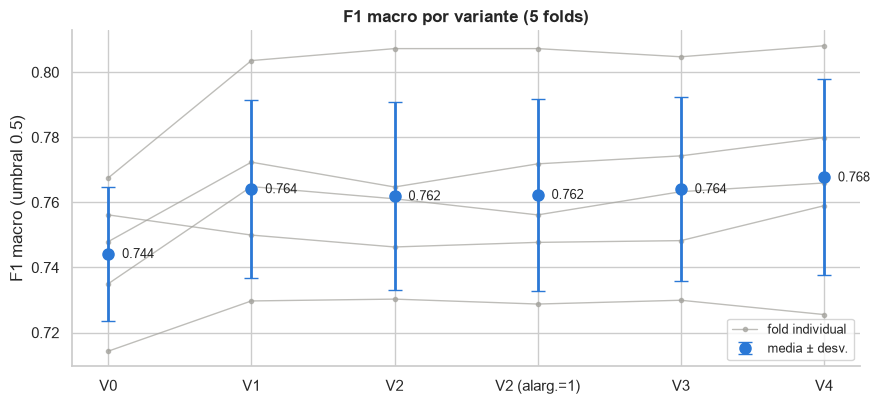

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(results)
x = np.arange(len(names))
for k in range(folds.nunique()):
    ax.plot(x, [results[n]["per_fold"]["F1_macro"].iloc[k] for n in names], color=MUTED, lw=1, alpha=0.7,
            marker="o", ms=3, label="fold individual" if k == 0 else None)
means = [results[n]["per_fold"]["F1_macro"].mean() for n in names]
stds = [results[n]["per_fold"]["F1_macro"].std() for n in names]
ax.errorbar(x, means, yerr=stds, fmt="o", color=ACCENT, ms=8, capsize=5, lw=2, label="media ± desv.")
for xi, m in zip(x, means):
    ax.annotate(f"{m:.3f}", (xi, m), textcoords="offset points", xytext=(10, -3), fontsize=9)
ax.set(xticks=x, xticklabels=names, ylabel="F1 macro (umbral 0.5)", title="F1 macro por variante (5 folds)")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
savefig(fig, "variants_f1")
plt.show()

**Interpretación:**
- **El único salto claro es V0 → V1** (limpieza + minúsculas): el F1 macro sube de 0.744 ± 0.020 a **0.764 ± 0.027**. La diferencia pareada es +0.020 ± 0.016 y V1 gana en 4 de los 5 folds.
- **De V1 a V4 todo queda dentro del ruido.** V2 0.762, V2 con alargamientos a 1 letra 0.762, V3 0.764 y V4 0.768. La mayor diferencia con V1, la de V4, es +0.0036 ± 0.0053, unas **8 veces menor que la desviación entre folds (≈0.03)**.
- Recortar los alargamientos a 1 o a 2 letras da lo mismo (0.7623 frente a 0.7619).
- Por etiqueta, TR es la más fácil (F1 ≈ 0.80) y AG la más difícil (≈ 0.73).

### F1 con umbral optimizado por etiqueta (cifra optimista)

El umbral 0.5 no tiene por qué ser el óptimo para el F1. Buscamos, para cada etiqueta, el umbral que maximiza el F1 sobre **todas las predicciones OOF**.

⚠️ Esta cifra es **optimista**: el umbral se elige con los mismos datos con los que se mide. Sirve para ver cuánto margen da ajustar el umbral, no como estimación del resultado en Kaggle. Para una estimación honesta, el umbral tendría que elegirse dentro de cada fold.

In [16]:
GRID = np.round(np.arange(0.10, 0.91, 0.01), 2)


def best_thresholds(y_true, proba) -> dict:
    return {lab: float(GRID[np.argmax([evaluate_oof(y_true, proba, np.where(np.arange(3) == j, t, 0.5))[f"F1_{lab}"]
                                       for t in GRID])]) for j, lab in enumerate(LABELS)}


rows = []
for name, r in results.items():
    thr = best_thresholds(Y, r["oof"])
    at05, opt = evaluate_oof(Y, r["oof"], 0.5), evaluate_oof(Y, r["oof"], thr)
    rows.append({"variante": name, "OOF macro (0.5)": at05["F1_macro"], "OOF micro (0.5)": at05["F1_micro"],
                 "OOF macro (umbral opt.)": opt["F1_macro"], "OOF micro (umbral opt.)": opt["F1_micro"],
                 **{f"umbral {lab}": thr[lab] for lab in LABELS}})
display(pd.DataFrame(rows).set_index("variante").round(3))

,OOF macro (0.5),OOF micro (0.5),OOF macro (umbral opt.),OOF micro (umbral opt.),umbral HS,umbral TR,umbral AG
variante,,,,,,,
V0,0.745,0.743,0.754,0.753,0.41,0.45,0.42
V1,0.764,0.762,0.776,0.774,0.45,0.47,0.45
V2,0.762,0.760,0.771,0.769,0.44,0.48,0.44
V2 (alarg.=1),0.763,0.761,0.773,0.771,0.45,0.49,0.45
V3,0.764,0.763,0.776,0.774,0.46,0.47,0.45
V4,0.768,0.766,0.778,0.776,0.47,0.47,0.44


**Interpretación:** optimizar el umbral sobre las predicciones OOF sube el F1 macro de V1 de 0.764 a 0.776 (+0.012). Los umbrales óptimos quedan entre 0.44 y 0.49 en todas las variantes, ligeramente por debajo de 0.5. Repetimos: es una cifra **optimista**. En los notebooks de modelos el umbral se elegirá dentro de la validación cruzada.

## 4. Ablación: ¿qué aporta cada paso?

Partimos de la variante con mayor F1 macro medio y desactivamos **un paso cada vez**, dejando todo lo demás igual. Si quitar un paso hace caer el F1 de forma consistente (en la mayoría de folds y más que el ruido), ese paso aporta. Si no cae, o sube, el paso sobra.

In [17]:
best_name = max(results, key=lambda n: results[n]["per_fold"]["F1_macro"].mean())
best_variant = pp.VARIANTS[best_name]
active = [s for s in pp.ABLATION_STEPS if getattr(best_variant, s)]
print(f"Variante de partida: {best_name} | pasos activos: {active}")

ablation = {best_name: results[best_name]}
for step in active:
    v = best_variant.without(step)
    ablation[f"sin {step}"] = run_cv(views_for(v), views_of(v))

base = ablation[best_name]["per_fold"]["F1_macro"]
abl_rows = []
for name, r in ablation.items():
    if name == best_name:
        continue
    d = r["per_fold"]["F1_macro"] - base
    abl_rows.append({"ablación": name, "F1 macro": r["per_fold"]["F1_macro"].mean(),
                     "Δ al quitarlo (media)": d.mean(), "Δ desv.": d.std(), "folds en que cae": int((d < 0).sum()),
                     **{f"Δ {lab}": (r["per_fold"][f"F1_{lab}"] - ablation[best_name]["per_fold"][f"F1_{lab}"]).mean()
                        for lab in LABELS}})
abl_table = pd.DataFrame(abl_rows).set_index("ablación").sort_values("Δ al quitarlo (media)").round(4)
display(abl_table)

Variante de partida: V4 | pasos activos: ['artifacts', 'users', 'urls', 'hashtags', 'rt', 'lower', 'elong', 'laughs', 'censor', 'restore', 'lemma']


,F1 macro,Δ al quitarlo (media),Δ desv.,folds en que cae,Δ HS,Δ TR,Δ AG
ablación,,,,,,,
sin lower,0.7494,-0.0183,0.0084,5,-0.0112,-0.0197,-0.0239
sin lemma,0.7641,-0.0036,0.0055,4,0.0033,-0.0062,-0.0080
sin urls,0.7659,-0.0018,0.0043,3,0.0050,-0.0028,-0.0075
sin users,0.7670,-0.0007,0.0066,1,-0.0006,-0.0009,-0.0007
sin elong,0.7672,-0.0005,0.0020,3,-0.0014,-0.0006,0.0005
sin restore,0.7672,-0.0005,0.0060,3,0.0021,0.0006,-0.0041
sin hashtags,0.7679,0.0002,0.0037,3,0.0027,-0.0011,-0.0010
sin rt,0.7680,0.0003,0.0006,0,0.0000,0.0008,0.0000
sin laughs,0.7702,0.0025,0.0028,1,0.0035,0.0045,-0.0005


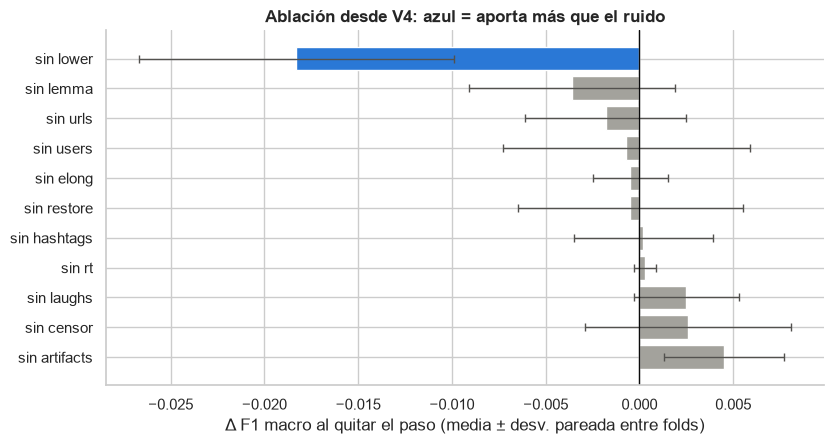

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
t = abl_table.iloc[::-1]
colors = [ACCENT if (v < 0 and -v > sd) else MUTED for v, sd in zip(t["Δ al quitarlo (media)"], t["Δ desv."])]
ax.barh(t.index, t["Δ al quitarlo (media)"], xerr=t["Δ desv."], color=colors, capsize=3,
        error_kw={"ecolor": "#52514e", "lw": 1})
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set(xlabel="Δ F1 macro al quitar el paso (media ± desv. pareada entre folds)",
       title=f"Ablación desde {best_name}: azul = aporta más que el ruido")
fig.tight_layout()
savefig(fig, "ablation")
plt.show()

**Interpretación** (ablación desde V4, la de mayor media):
- **Solo las minúsculas aportan de forma clara.** Sin ellas el F1 macro cae −0.018 ± 0.008, en los 5 folds y en las tres etiquetas (HS −0.011, TR −0.020, AG −0.024).
- **El resto de pasos queda dentro del ruido:** lemas −0.0036 ± 0.0055, URLs −0.0018, usuarios −0.0007, alargamientos −0.0005, restauración −0.0005. Quitar la normalización de risas (+0.0025) o de censura (+0.0026) incluso sube un poco el F1, también dentro del ruido.
- **Quitar la limpieza de artefactos "mejora" el F1** (+0.0045 ± 0.0032, en los 5 folds), y lo hace casi solo en **AG (+0.014)**. No es una mejora lingüística: sin limpiar, los n-gramas de caracteres ven las comillas duplicadas `""`, que marcan las 51 filas del artefacto con AG=1 (H3), y el modelo aprende ese atajo. **Mantenemos la limpieza.** Si se quiere explotar el artefacto en el test, es la pregunta abierta P3 y debe hacerse de forma explícita, no por accidente.

## 5. ¿Qué vista usar: palabras, caracteres o ambas?

Con el mismo texto preprocesado comparamos usar solo las palabras (1–2 gramas), solo los n-gramas de caracteres (2–5), ambas, y ambas más lemas. Los **n-gramas de caracteres** capturan fragmentos de palabra (*llate*, *perr*), así que son robustos a errores, alargamientos y palabras dañadas. Las **palabras** capturan unidades completas y bigramas (*eres una*).

In [19]:
view_text = views_for(pp.V4)  # contiene 'text' (pasos a-e) y 'lemmas'
view_sets = {"solo palabras": ("word",), "solo caracteres": ("char",), "palabras + caracteres": ("word", "char"),
             "palabras + caracteres + lemas": ("word", "char", "lemma"), "solo lemas": ("lemma",)}
view_results = {name: run_cv(view_text, v) for name, v in view_sets.items()}
display(summarize(view_results))
display(paired(view_results, "palabras + caracteres"))

,F1_HS,F1_TR,F1_AG,F1_macro,F1_micro
solo palabras,0.711 ± 0.030,0.770 ± 0.039,0.717 ± 0.029,0.733 ± 0.027,0.730 ± 0.026
solo caracteres,0.749 ± 0.018,0.768 ± 0.036,0.706 ± 0.024,0.741 ± 0.024,0.740 ± 0.023
palabras + caracteres,0.764 ± 0.031,0.797 ± 0.032,0.732 ± 0.026,0.764 ± 0.028,0.762 ± 0.028
palabras + caracteres + lemas,0.760 ± 0.035,0.803 ± 0.032,0.740 ± 0.028,0.768 ± 0.030,0.765 ± 0.030
solo lemas,0.707 ± 0.021,0.774 ± 0.034,0.706 ± 0.023,0.729 ± 0.025,0.726 ± 0.024


,F1_macro medio,desv. entre folds,Δ vs palabras + caracteres (media),Δ desv.,folds mejor
variante,,,,,
solo palabras,0.7326,0.0271,-0.0315,0.0059,0
solo caracteres,0.7407,0.0235,-0.0234,0.0115,0
palabras + caracteres,0.7641,0.0282,0.0000,0.0000,0
palabras + caracteres + lemas,0.7677,0.0302,0.0036,0.0055,4
solo lemas,0.7290,0.0246,-0.0351,0.0085,0


**Interpretación:**
- **Palabras + caracteres es claramente mejor que cualquiera por separado.** Gana a solo palabras por +0.0315 ± 0.0059 y a solo caracteres por +0.0234 ± 0.0115, en los 5 folds en ambos casos.
- Las dos vistas son complementarias: los caracteres son mejores en HS (0.749 frente a 0.711) y las palabras en AG (0.717 frente a 0.706). En TR empatan (0.770 frente a 0.768).
- Los lemas solos son la peor vista (0.729), y añadirlos a palabras + caracteres da +0.0036 ± 0.0055, dentro del ruido.

**Decisión: palabras + caracteres.**

### Elección de la variante

**Regla:** entre las variantes cuyo F1 macro **no es consistentemente peor** que el de la mejor, elegimos la **más simple**. "Consistentemente peor" significa que la diferencia pareada media con la mejor supera su propia desviación entre folds. Orden de simplicidad: V0 < V1 < V2 < V3 < V4 (cada una añade pasos a la anterior). Si una variante más compleja no mejora más allá del ruido, no compensa su coste.

In [20]:
ORDER = ["V0", "V1", "V2", "V2 (alarg.=1)", "V3", "V4"]
best_pf = results[best_name]["per_fold"]["F1_macro"]
sel_rows = []
for name in ORDER:
    d = best_pf - results[name]["per_fold"]["F1_macro"]
    sel_rows.append({"variante": name, "F1 macro": results[name]["per_fold"]["F1_macro"].mean(),
                     f"Δ {best_name} − variante (media)": d.mean(), "Δ desv.": d.std(),
                     "¿consistentemente peor?": bool(d.mean() > d.std()) if name != best_name else False})
sel = pd.DataFrame(sel_rows).set_index("variante").round(4)
display(sel)
CHOSEN = pp.VARIANTS[next(n for n in ORDER if not sel.loc[n, "¿consistentemente peor?"])]
print(f"Variante elegida: {CHOSEN.name} | pasos: {[k for k, v in CHOSEN.steps().items() if v]}")

,F1 macro,Δ V4 − variante (media),Δ desv.,¿consistentemente peor?
variante,,,,
V0,0.7442,0.0235,0.0158,True
V1,0.7641,0.0036,0.0053,False
V2,0.7619,0.0058,0.0082,False
V2 (alarg.=1),0.7623,0.0054,0.0062,False
V3,0.7641,0.0036,0.0055,False
V4,0.7677,0.0000,0.0000,False


Variante elegida: V1 | pasos: ['artifacts', 'users', 'urls', 'hashtags', 'rt', 'lower']


**Interpretación:** V0 queda **consistentemente peor** que la mejor (diferencia 0.0235 > desviación 0.0158). Las demás están empatadas con V4 dentro del ruido; por ejemplo, V1 queda a 0.0036 con una desviación de 0.0053. Por la regla de simplicidad, **la variante elegida es V1** (limpieza + minúsculas). Los pasos c–f no se descartan por perjudicar, sino por **no demostrar beneficio** con este modelo. Se guarda también V4 por si un modelo más fuerte los aprovecha.

## 6. Jerarquía como regla de posprocesamiento

En el train, **TR=1 implica siempre HS=1** (EDA, H2). Los modelos por etiqueta son independientes y pueden predecir TR=1 con HS=0, algo que nunca ocurre en los datos. Probamos una regla sencilla sobre las predicciones OOF: **si P(HS) < 0.5, forzar TR=0**. También probamos la versión que fuerza TR=0 y AG=0. Para AG, la jerarquía tiene 26 excepciones, todas del artefacto de comillas (H3).

In [21]:
def apply_hierarchy(proba: np.ndarray, hs_threshold: float = 0.5, also_ag: bool = False) -> np.ndarray:
    """Pone a 0 la probabilidad de TR (y opcionalmente AG) cuando P(HS) < hs_threshold."""
    out = proba.copy()
    low_hs = out[:, 0] < hs_threshold
    out[low_hs, 1] = 0.0
    if also_ag:
        out[low_hs, 2] = 0.0
    return out


ref_name = CHOSEN.name  # se evalúa sobre la variante elegida
oof = results[ref_name]["oof"]
pred = (oof >= 0.5).astype(int)
print(f"Predicciones OOF de {ref_name} incoherentes: TR=1 con HS=0 -> {int(((pred[:, 1] == 1) & (pred[:, 0] == 0)).sum())}, "
      f"AG=1 con HS=0 -> {int(((pred[:, 2] == 1) & (pred[:, 0] == 0)).sum())}")

post = {"sin regla": oof, "HS<0.5 ⇒ TR=0": apply_hierarchy(oof), "HS<0.5 ⇒ TR=0 y AG=0": apply_hierarchy(oof, also_ag=True)}
rows = []
for name, p in post.items():
    per_fold = pd.DataFrame([evaluate_oof(Y[(folds == k).to_numpy()], p[(folds == k).to_numpy()]) for k in sorted(folds.unique())])
    rows.append({"regla": name, **{m: f"{per_fold[m].mean():.3f} ± {per_fold[m].std():.3f}" for m in METRICS},
                 "Δ macro (media pareada)": (per_fold["F1_macro"] - results[ref_name]["per_fold"]["F1_macro"]).mean(),
                 "folds mejor": int((per_fold["F1_macro"] > results[ref_name]["per_fold"]["F1_macro"]).sum())})
display(pd.DataFrame(rows).set_index("regla").round(4))

Predicciones OOF de V1 incoherentes: TR=1 con HS=0 -> 47, AG=1 con HS=0 -> 28


,F1_HS,F1_TR,F1_AG,F1_macro,F1_micro,Δ macro (media pareada),folds mejor
regla,,,,,,,
sin regla,0.761 ± 0.022,0.800 ± 0.039,0.731 ± 0.028,0.764 ± 0.027,0.762 ± 0.027,0.0000,0
HS<0.5 ⇒ TR=0,0.761 ± 0.022,0.802 ± 0.034,0.731 ± 0.028,0.765 ± 0.023,0.762 ± 0.023,0.0004,2
HS<0.5 ⇒ TR=0 y AG=0,0.761 ± 0.022,0.802 ± 0.034,0.723 ± 0.022,0.762 ± 0.022,0.760 ± 0.022,-0.0022,2


**Interpretación:**
- Las predicciones OOF de V1 contienen **47 casos incoherentes** (TR=1 con HS=0) y 28 con AG=1 y HS=0.
- La regla **HS < 0.5 ⇒ TR=0** los elimina. El F1 de TR pasa de 0.800 a 0.802 y el macro de 0.764 a 0.765 (+0.0004, mejor en 2 de 5 folds): **efecto nulo dentro del ruido**, pero sin coste y con predicciones coherentes.
- Extender la regla a AG **empeora** AG (0.731 → 0.723; macro −0.0022). Muchos AG=1 tienen P(HS) por debajo de 0.5, y además la jerarquía de AG no es estricta en los datos (H3).

Recomendación: aplicar solo la regla de TR, como regla de coherencia, y volver a probarla con un modelo en cascada.

## 7. Test: ¿el preprocesamiento produce lo mismo que en train?

Aplicamos al test la variante elegida, con el **mismo diccionario de restauración del train**, y comprobamos que el resultado se parece al del train en dos aspectos:

- la frecuencia de los tokens especiales (`<USER>`, `<URL>`, `jaja`) y de las palabras restauradas;
- la **tasa de palabras fuera de vocabulario (OOV)**: el porcentaje de tokens del test que no aparecen en el vocabulario del train. Como referencia justa, calculamos la misma tasa dentro del train: tokens de cada fold de validación que no aparecen en los otros 4 folds.

En el EDA comprobamos que **el test tampoco trae tildes ni ñ** (H14), así que no hace falta aplicarle una pérdida de caracteres adicional. Aun así, `clean_text` borra los no ASCII de cualquier texto, de modo que si un test futuro trajera tildes quedaría igual que el train.

In [22]:
def token_stats(texts: pd.Series) -> dict:
    toks = [w for t in texts for w in re.findall(TOKEN_PATTERN, t)]
    return {"tuits": len(texts), "tokens por tuit": len(toks) / len(texts),
            "% tuits con <USER>": 100 * texts.str.contains("<USER>", regex=False).mean(),
            "% tuits con <URL>": 100 * texts.str.contains("<URL>", regex=False).mean(),
            "% tuits con risa": 100 * texts.map(lambda t: pp.RE_LAUGH.search(t) is not None).mean(),
            "% tuits vacíos": 100 * (texts.str.strip() == "").mean()}


train_proc = train["text"].map(lambda t: pp.apply_variant(t, CHOSEN, restore_dict))
vocab_of = lambda s: set(w for t in s for w in re.findall(TOKEN_PATTERN, t))
oov_rate = lambda s, vocab: 100 * np.mean([w not in vocab for t in s for w in re.findall(TOKEN_PATTERN, t)])

cv_oov = [oov_rate(train_proc[folds == k], vocab_of(train_proc[folds != k])) for k in sorted(folds.unique())]
stats = {"train": {**token_stats(train_proc), "% tokens OOV": np.mean(cv_oov)}}
if HAS_TEST:
    test_proc = test["text"].map(lambda t: pp.apply_variant(t, CHOSEN, restore_dict))
    stats["test"] = {**token_stats(test_proc), "% tokens OOV": oov_rate(test_proc, vocab_of(train_proc))}
    restored_share = lambda s: 100 * np.mean([w in restore_dict for t in s for w in pp.RE_WORD.findall(t)])
    pre_restore = lambda s: s.map(lambda t: pp.apply_variant(t, replace(CHOSEN, restore=False)))
    stats["train"]["% tokens restaurables (dicc.)"] = restored_share(pre_restore(train["text"]))
    stats["test"]["% tokens restaurables (dicc.)"] = restored_share(pre_restore(test["text"]))
display(pd.DataFrame(stats).round(2))
print("OOV del train por fold (val vs. train del fold):", np.round(cv_oov, 2))

,train,test
tuits,1731.00,1154.00
tokens por tuit,17.20,16.76
% tuits con <USER>,47.43,45.75
% tuits con <URL>,31.20,28.34
% tuits con risa,6.30,4.85
% tuits vacíos,0.00,0.52
% tokens OOV,16.22,15.30
% tokens restaurables (dicc.),4.44,4.32


OOV del train por fold (val vs. train del fold): [16.6  15.91 16.28 15.86 16.43]


**Interpretación:** el test procesado se parece mucho al train:
- tokens por tuit: 16.8 frente a 17.2;
- `<USER>`: 45.8% frente a 47.4%; `<URL>`: 28.3% frente a 31.2%; risa: 4.9% frente a 6.3%;
- tokens restaurables por el diccionario: 4.3% frente a 4.4%.

La **tasa OOV del test (15.3%)** es incluso algo menor que la estimada dentro del train (16.2%, entre 15.9% y 16.6% según el fold), porque el test se compara con el train completo y no con 4/5 de él. El 0.52% de tuits vacíos del test son las 6 celdas `#¿NOMBRE?`; necesitarán una predicción por defecto.

**El test no trae tildes ni ñ**, así que no se le aplica ninguna pérdida extra de caracteres. `clean_text` borra los no ASCII de todos modos, de forma que un test con tildes quedaría igual que el train.

## 8. Guardado del texto procesado

Guardamos el texto procesado de la variante elegida para que los notebooks siguientes no tengan que recalcularlo:

- `data/processed/train_<variante>.parquet`: `id`, texto original, texto procesado, etiquetas y fold (y `lemmas` si la variante lematiza).
- `data/processed/test_<variante>.parquet`: `id`, texto original y texto procesado (y `lemmas`).
- Además de la variante elegida guardamos **V4** (pipeline completo con lemas). Si un modelo posterior más fuerte quiere volver a probar los pasos c–f, no tendrá que recalcularlos.
- `data/processed/restore_dict.json`: el diccionario de restauración usado.
- `data/processed/lemma_cache.parquet`: caché de spaCy (texto procesado → lemas). Es determinista y no depende de las etiquetas.

Los CSV originales de `data/` no se modifican.

In [23]:
def save_processed(variant) -> list:
    """Guarda train/test procesados con la variante dada (con columna 'lemmas' solo si la variante lematiza)."""
    paths = []
    for split, df in [("train", train), ("test", test)]:
        if df is None:
            continue
        views = pp.build_views(df["text"], variant, restore_dict, lemma_cache=lemma_cache, nlp=nlp)
        out = pd.DataFrame({"id": df["id"], "text_raw": df["text"], **views})
        if split == "train":
            out = out.assign(**{lab: df[lab] for lab in LABELS}, fold=folds)
        paths.append(PROCESSED_DIR / f"{split}_{variant.name}.parquet")
        out.to_parquet(paths[-1], index=False)
    return paths


# Variante elegida + V4 (pipeline completo con lemas) como alternativa para modelos más fuertes
saved = save_processed(CHOSEN) + ([] if CHOSEN.name == "V4" else save_processed(pp.V4))
(PROCESSED_DIR / "restore_dict.json").write_text(json.dumps(restore_dict, ensure_ascii=True, indent=0, sort_keys=True))
pd.DataFrame({"text": list(lemma_cache), "lemmas": list(lemma_cache.values())}).to_parquet(
    PROCESSED_DIR / "lemma_cache.parquet", index=False)
for p in saved + [PROCESSED_DIR / "restore_dict.json", PROCESSED_DIR / "lemma_cache.parquet"]:
    print(f"{p.relative_to(PROCESSED_DIR.parent.parent)}  ({p.stat().st_size / 1024:.0f} KB)")
check = pd.read_parquet(saved[0])
print(check.shape, "| ¿texto igual al recalculado?", (check["text"] == train_proc.values).all())
display(check.head(3)[["id", "text", "HS", "TR", "AG", "fold"]])

data/processed/train_V1.parquet  (256 KB)
data/processed/test_V1.parquet  (166 KB)
data/processed/train_V4.parquet  (349 KB)
data/processed/test_V4.parquet  (228 KB)
data/processed/restore_dict.json  (4 KB)
data/processed/lemma_cache.parquet  (729 KB)
(1731, 7) | ¿texto igual al recalculado? True


,id,text,HS,TR,AG,fold
0,20430,<USER> amigos saime mi nombre es walter perez v-13.899.989 wperez001@gmail.com y desde el 16/03/2017 que fui a cita aun no me imprimen e...,0,0,0,0
1,22434,preferan enfrentar los peligros de regresar a su hogar antes que ser encarcelados en estas condiciones seal la organizacin que tambin de...,0,0,0,2
2,23930,<USER> siiii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,0,0,0,4


## 9. Decisiones

### Variante elegida y justificación

| Decisión | Elección | Evidencia (F1 macro, 5 folds, umbral 0.5) |
|---|---|---|
| **Variante base** | **V1** = limpieza + minúsculas | V1 0.764 ± 0.027 frente a V0 0.744 ± 0.020 (Δ pareada +0.020 ± 0.016, 4/5 folds). V2–V4 a ±0.006 de V1, muy por debajo de la desviación entre folds (≈0.03) |
| Minúsculas | Sí | La ablación cae −0.018 ± 0.008 en 5/5 folds: el único paso con efecto claro |
| Limpieza de artefactos del CSV | Sí | Quitarla "mejora" solo AG (+0.014) porque deja ver el artefacto H3. No es señal lingüística (ver P3) |
| `<USER>`, `<URL>`, hashtags, RT | Sí (neutros) | Δ en la ablación dentro del ruido; se mantienen por coherencia y porque reducen el vocabulario |
| Alargamientos, risas y censura (V2) | No por defecto | V2 − V1 = −0.002 ± 0.004; recortar a 1 o 2 letras da lo mismo |
| Restauración de palabras dañadas (V3) | No por defecto | V3 − V1 = 0.000 ± 0.002. Los n-gramas de caracteres ya absorben la fragmentación |
| Lemas como vista extra (V4) | No por defecto | +0.0036 ± 0.0053 (dentro del ruido), con el coste añadido de spaCy |
| Vistas | Palabras + caracteres | +0.0315 frente a solo palabras y +0.0234 frente a solo caracteres, en 5/5 folds |
| Jerarquía | Aplicar HS < 0.5 ⇒ TR=0; no a AG | TR: +0.0004 (nulo, sin coste, coherente). AG: −0.0022 |
| Umbral | Optimizar dentro de la CV en los notebooks de modelos | +0.012 en OOF, pero optimista |
| Test | Misma función y mismo diccionario; sin pérdida extra de caracteres | Distribuciones de tokens y OOV parecidas (15.3% frente a 16.2%); 6 tuits vacíos → predicción por defecto |

Archivos para los notebooks siguientes: `data/processed/train_V1.parquet`, `test_V1.parquet`, `folds.csv` y, como alternativa, `train_V4.parquet` y `test_V4.parquet`.

### Límites del análisis

- **Tamaño:** con 1731 tuits, el F1 macro varía ≈0.02–0.03 entre folds. **Las diferencias menores que esa desviación no son significativas**, y por eso no elegimos entre V1, V2, V3 y V4 por sus diferencias de ±0.006. Con 5 folds, ni siquiera "mejor en 5/5" es una prueba fuerte (probabilidad 1/32 por azar).
- **Modelo fijo y simple:** que un paso sea neutro aquí no implica que lo sea con otros modelos. La restauración y los lemas podrían ayudar a representaciones sin n-gramas de caracteres (Word2Vec propio, léxicos), donde la fragmentación pesa más. Hay que volver a probarlos entonces.
- **Etiquetas de AG:** el artefacto H3 sigue en las etiquetas y afecta a cómo se evalúa AG (P2). Además, en 12 textos queda un `;` residual de esas filas.
- **Umbral:** el F1 con umbral optimizado sobre OOF está sesgado al alza.
- **Diccionarios propios:** la restauración se construyó con observaciones del EDA y reglas sin etiquetas, pero puede tener errores puntuales (formas ambiguas como *t* → *tu*, *est* → *esta*).